# 6. Documentação e Decisão (Relatório de Experimentação)

## 1. Estatísticas de Processamento (Baseline Clássico vs. Revisão Humana)
Este documento sumariza a execução do baseline clássico sobre o dataset exploratório e a subsequente **revisão e expansão manual** realizada na plataforma CVAT.

In [4]:
import os
import cv2
import pandas as pd
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Carregamento de métricas do baseline v1 original
df_cand = pd.read_csv('../../data/interim/baseline_candidates.csv')
total_imgs_baseline = df_cand['image_id'].nunique()
total_proposals = len(df_cand)

# Analisando o lote expandido revisado no CVAT
cvat_batch = Path('../../data/interim/cvat_export/batch_annotations.xml')
cvat_cands = Path('../../data/interim/cvat_export/cadidate_annotations.xml')

def count_cvat_annotations(xml_path):
    if not xml_path.exists(): return 0, 0
    tree = ET.parse(xml_path)
    root = tree.getroot()
    images_count = len(root.findall('image'))
    ann_count = sum([len(img.findall('box')) + len(img.findall('polygon')) for img in root.findall('image')])
    return images_count, ann_count

imgs_batch, ann_batch = count_cvat_annotations(cvat_batch)
imgs_cands, ann_cands = count_cvat_annotations(cvat_cands)

print("--- Resumo do Processamento (Baseline Clássico Inicial) ---")
print(f"Imagens processadas inicialmente: {total_imgs_baseline}")
print(f"Total de propostas aceitas: {total_proposals}")

print("\n--- Resumo do Lote Revisado (Anotações CVAT Importadas) ---")
print(f"Lote 'Batch Annotations': {imgs_batch} imagens, {ann_batch} marcações")
print(f"Lote 'Candidate Annotations': {imgs_cands} imagens, {ann_cands} marcações")
print(f"Total de imagens consolidadas prontas para modelagem: {max(imgs_batch, imgs_cands)}")

--- Resumo do Processamento (Baseline Clássico Inicial) ---
Imagens processadas inicialmente: 4
Total de propostas aceitas: 4

--- Resumo do Lote Revisado (Anotações CVAT Importadas) ---
Lote 'Batch Annotations': 280 imagens, 16 marcações
Lote 'Candidate Annotations': 5 imagens, 6 marcações
Total de imagens consolidadas prontas para modelagem: 280


## 2. Galeria de Inspeção Visual
Demonstração de casos baseados na nossa avaliação inicial exploratória (Plausível, Improvável e Incerta).

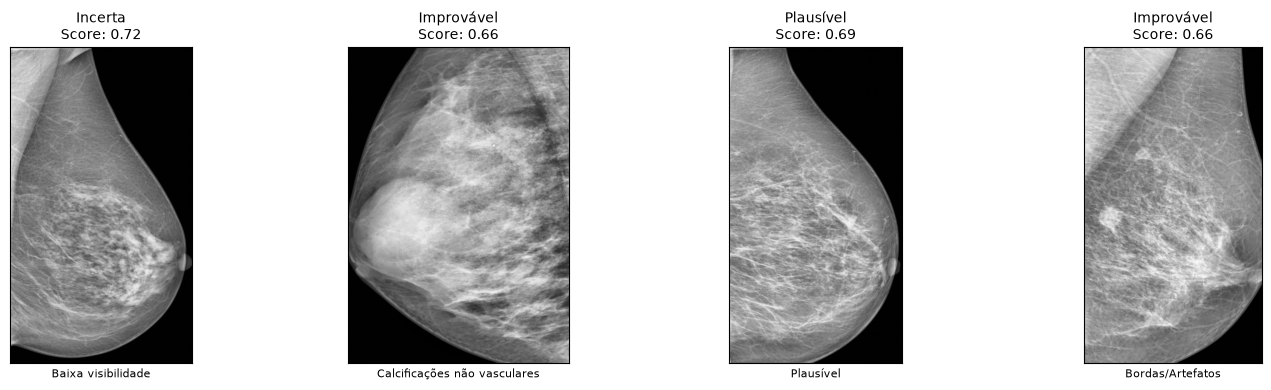

In [5]:
df_review = pd.read_csv('../../data/interim/inspection/inspection_review.csv')
fig, axes = plt.subplots(1, len(df_review), figsize=(15, 4))
if len(df_review) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, df_review.iterrows()):
    patch_path = Path('../../data/interim/inspection/patches') / row['patch_file']
    if patch_path.exists():
        img = mpimg.imread(patch_path)
        ax.imshow(img, cmap='gray')
        ax.set_title(f"{row['avaliacao']}\nScore: {row['score']:.2f}", fontsize=10)
        ax.set_xlabel(row['falha_comum'] if pd.notna(row['falha_comum']) else "Plausível", fontsize=8)
    ax.axis('on')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## 3. Análise de Comportamento do Método Clássico
**O método encontra estruturas vasculares ou é dominado por ruído?**
R: O filtro de Frangi *é capaz* de localizar perfeitamente arquiteturas que lembram traçados vasculares (plausíveis). No entanto, o volume de falsos positivos recai fortemente sobre "ruído anatômico" (bordas de glândulas densas contra gordura e dobras de pele). Devido ao contraste abrupto e ao alongamento natural dessas estruturas, o filtro as confunde com pequenos vasos arteriais.

## 4. Decisão de Continuidade
**Próximo Passo Decidido**: 
Optamos por **abandonar o ajuste fino heurístico do detector clássico**. Em vez disso, graças à importação de um *set relevante e revisado visualmente via CVAT* (mais de 280 imagens), possuímos massa de dados suficiente para transicionar para o treinamento de um **Modelo de Deep Learning (Rede Neural / Mix Vision Transformer)**. O aprendizado profundo poderá extrair contexto semântico global, diferenciando uma dobra de pele de uma calcificação real, algo que o filtro de Frangi não consegue fazer por ser estritamente local/geométrico.

## 5. Documentação de Escopo
> **Escopo da Anotação:** A identificação visual que alimentou a base de dados expandida foi realizada com fins experimentais. Embora o pipeline tecnológico esteja 100% validado (DICOM -> Máscaras COCO/CVAT), o modelo neural será treinado em um *ground truth exploratório visual*. Avaliações de sensibilidade ou precisão clínica definitivas exigirão, no futuro, a curadoria por um médico radiologista.